# Figure 4A–B - Cytoarchitecture and Glx/GABA+


In [1]:
from pathlib import Path
import sys
base_path = base_path = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "CODE").is_dir() and (p / "DATA").is_dir()
)
sys.path.insert(0, str(Path(base_path) / 'CODE'))


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os


In [3]:
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from matplotlib.colors import LinearSegmentedColormap

In [4]:
AX_GREY = "#757575"

TITLE_FS = 16      
LABEL_FS = 32       
TICK_FS  = 35     
MARKERS = 100
LINE = 4
ALPHA = 0.2

LABEL_FS = 35
TICK_FS = 35
figsize = (15,9)

LABEL_FS = 35
TICK_FS = 35
figsize = (13, 9)

output_dir = f"{base_path}/FIGURES/main/Fig_4"
os.makedirs(output_dir, exist_ok=True)

## 4A: BigBrain Model

In [5]:
bb_colors = {5: "#7f297e", 4: "#37699c", 3: "#aad58c", 2: "#f4ee1d"}

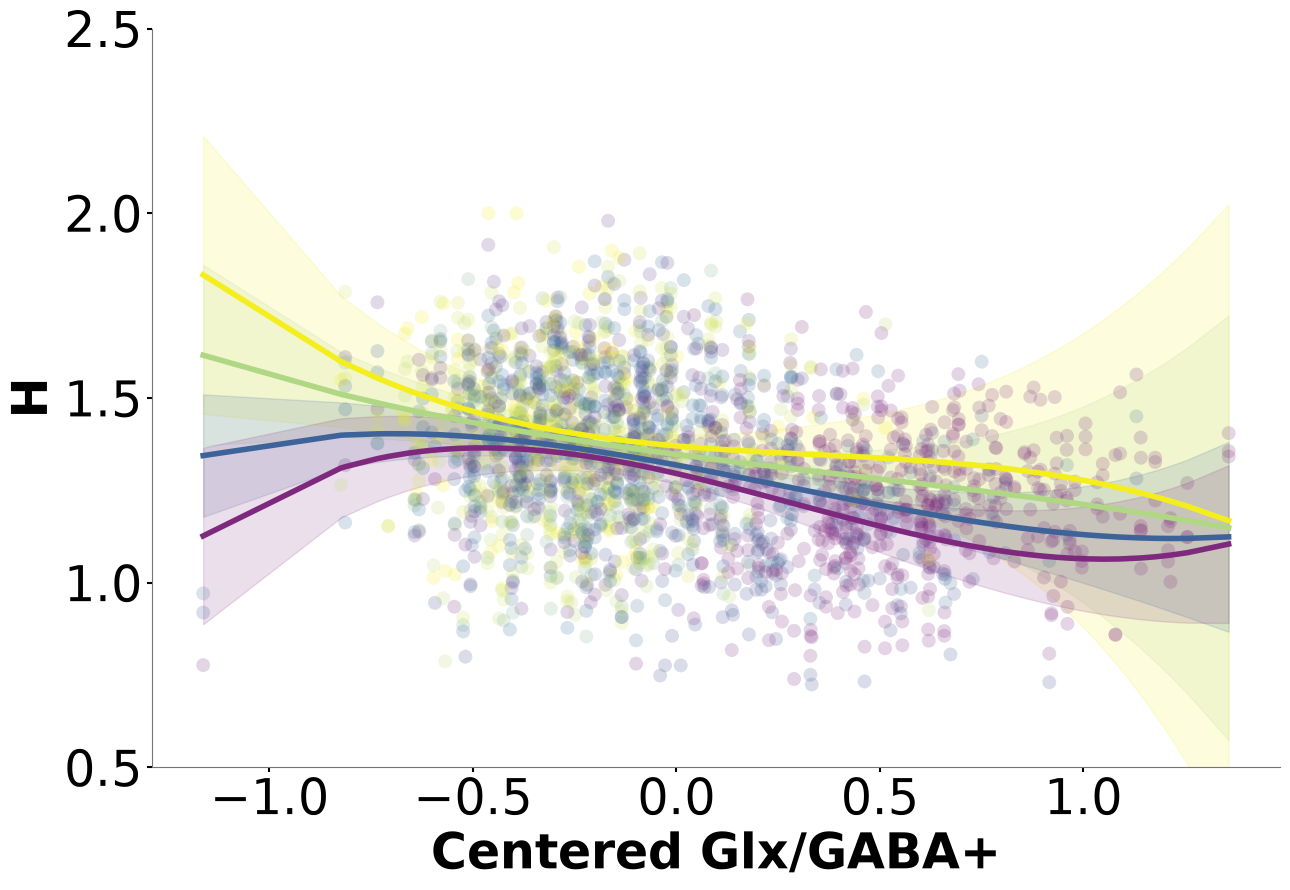

In [6]:
preds = pd.read_csv(f"{base_path}/RESULTS/discovery_dataset/models/bigbrain_model.csv")
raw = pd.read_csv(f"{base_path}/RESULTS/discovery_dataset/models/bigbrain_raw.csv")

bb_cmap = bb_cmap = LinearSegmentedColormap.from_list(
    "bigbrain",
    [bb_colors[k] for k in sorted(bb_colors)],
    N=256
)

cmap = bb_cmap 

fig, ax = plt.subplots(figsize=figsize)
norm = Normalize(vmin=raw["Gradient_c"].min(), vmax=raw["Gradient_c"].max())

sc = ax.scatter(raw["EIB_c"], raw["Hursts"], c=raw["Gradient_c"],
                 cmap=cmap, norm=norm, s=MARKERS, alpha=ALPHA,
                 edgecolor="none", zorder=1)

levels = sorted(preds["group"].unique())
level_labels = ["", "", "", ""]

for lev, lab in zip(levels, level_labels):
    col = cmap(norm(lev))
    sub = preds[preds["group"] == lev].sort_values("x")
    ax.plot(sub["x"], sub["predicted"], color=col,
            label=f"{lab} {lev:.2g}", linewidth=LINE, zorder=2)
    if {"conf.low", "conf.high"}.issubset(sub.columns):
        ax.fill_between(sub["x"], sub["conf.low"], sub["conf.high"],
                         color=col, alpha=0.15, zorder=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(AX_GREY)
ax.spines["bottom"].set_color(AX_GREY)

ax.set_xlabel("Centered Glx/GABA+", fontsize=LABEL_FS, fontweight="bold")
ax.set_ylabel("H", fontsize=LABEL_FS, fontweight="bold")
ax.tick_params(axis="both", labelsize=TICK_FS, width=1.5)

# #cbar = fig.colorbar(sc, ax=ax)
# cbar.set_label("Gradient", fontsize=LABEL_FS, fontweight="bold")
# cbar.ax.tick_params(labelsize=TICK_FS)

# ax.legend(title="Gradient level", frameon=False, fontsize=11, title_fontsize=12,
#           loc="center left", bbox_to_anchor=(1.02, 0.5))

ax.set_ylim([0.5, 2.5])

plt.tight_layout()
plt.savefig(f"{output_dir}/A_BigBrain.png", dpi=300, bbox_inches="tight")
plt.show()

## 4B: Von Economo

In [7]:
van_ec_colors = {1: "#7f297e", 2: "#37699c", 3: "#aad58c", 4: "#fcce0c", 5: "#f4ee1d"}

cyto_names = {
    1: "Agranular",
    2: "Frontal",
    3: "Parietal",
    4: "Polar",
    5: "Granular"
}

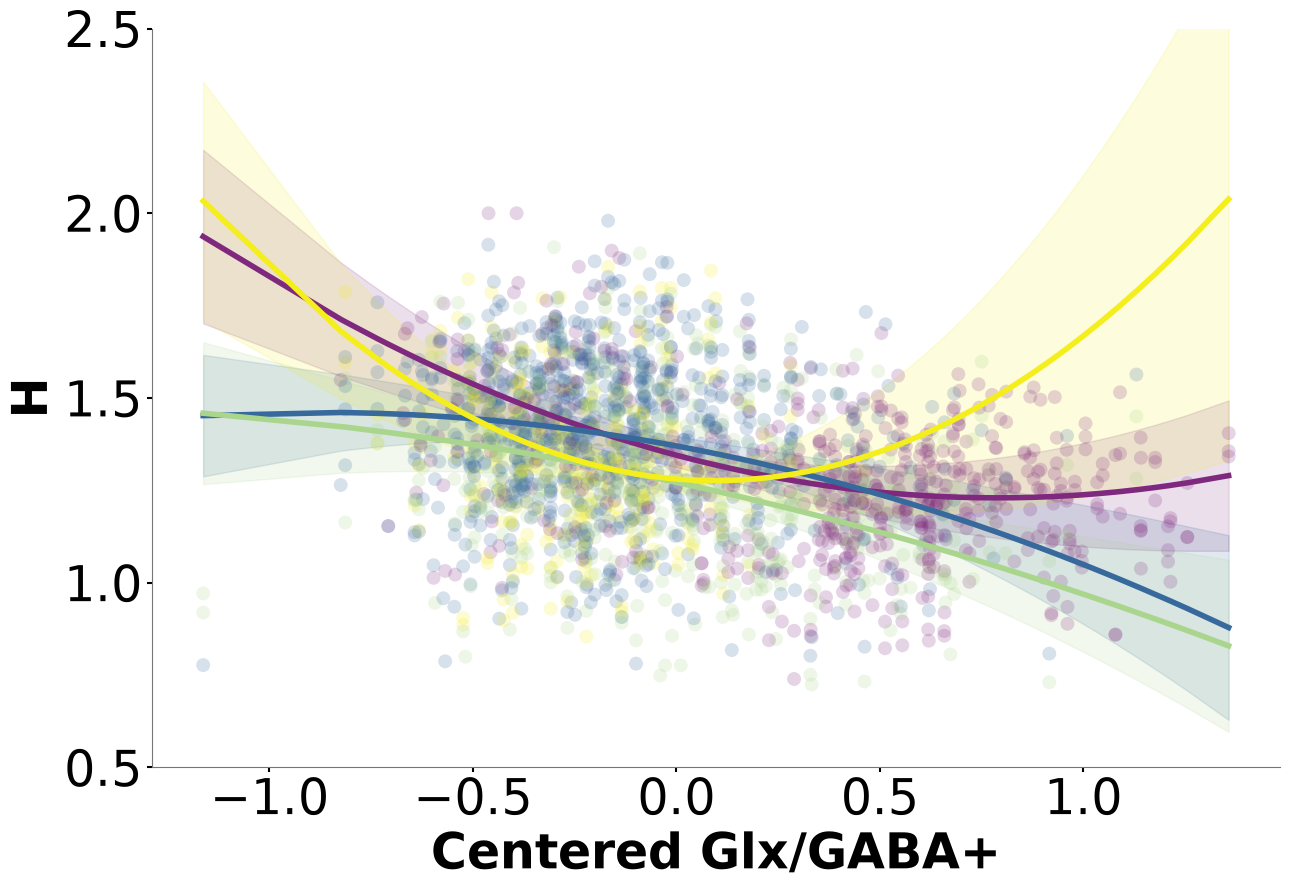

In [8]:
preds = pd.read_csv(f"{base_path}/RESULTS/discovery_dataset/models/von_economo_model.csv")
raw = pd.read_csv(f"{base_path}/RESULTS/discovery_dataset/models/von_economo_raw.csv")
fig, ax = plt.subplots(figsize=figsize)

# Scatter of raw data
scatter_colors = raw["Gradient"].map(van_ec_colors)
ax.scatter(raw["EIB_c"], raw["Hursts"], c=scatter_colors,
           s=MARKERS, alpha=ALPHA, edgecolor="none", zorder=1)

# Prediction lines
levels = sorted(preds["group"].unique())

for lev in levels:
    lev_int = int(lev)
    col = van_ec_colors.get(lev_int, "gray") 
    label = cyto_names.get(lev_int, f"Gradient = {lev_int}")
    sub = preds[preds["group"] == lev].sort_values("x")
    ax.plot(sub["x"], sub["predicted"], color=col,
            label=label, linewidth=LINE, zorder=2)
    if {"conf.low", "conf.high"}.issubset(sub.columns):
        ax.fill_between(sub["x"], sub["conf.low"], sub["conf.high"],
                         color=col, alpha=0.15, zorder=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(AX_GREY)
ax.spines["bottom"].set_color(AX_GREY)

ax.set_xlabel("Centered Glx/GABA+", fontsize=LABEL_FS, fontweight="bold")
ax.set_ylabel("H", fontsize=LABEL_FS, fontweight="bold")
ax.tick_params(axis="both", labelsize=TICK_FS, width=1.5)
# for label in ax.get_xticklabels() + ax.get_yticklabels():
#     label.set_fontweight("bold")

# ax.legend(title="Gradient", frameon=False, fontsize=11, title_fontsize=12,
#           loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_ylim(0.5, 2.5)
plt.tight_layout()
plt.savefig(f"{output_dir}/B_von_economo.png", dpi=300, bbox_inches="tight")
plt.show()